# S&P 500 5-Day Volatility Forecasting — Modeling & Evaluation

Uses the point-in-time CRSP panel produced by `S_P500_volatility_data_acquisition.ipynb` and `S_P500_volatility_data_preparation.ipynb`.

| Period | Dates | Use |
|---|---|---|
| Warm-up | 2019 | Feature history only |
| Train | 2020–2023 (last 5 trading days purged) | Fit models for selection |
| Validation | 2024 | Choose hyperparameters, model, and calibration factors |
| Refit | 2020–2024 (last 5 trading days of 2024 purged) | Final fit |
| Test | 2025 | Evaluated once |

**Target:** sum of squared daily log returns over t+1…t+5 (`y_var`). Reported as annualized volatility, √(252/5 · y_var).
**Sample:** a stock-date enters only if the stock is an S&P 500 member on date t. Its target still uses post-t returns, even if the stock later leaves the index.
**Primary selection metric:** QLIKE on variance (robust for noisy volatility proxies, Patton 2011). MAE/RMSE on annualized volatility are reported alongside.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os, time, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)

# Paths: Colab Drive first, then local copies
CANDIDATES = ["/content/drive/MyDrive/sp500_vol/sp500_panel_features.parquet",
              "sp500_panel_features.parquet", "/mnt/user-data/uploads/sp500_panel_features.parquet"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))

H = 5                      # forecast horizon (trading days)
ANN = 252 / H              # annualization for a 5-day variance
RS = 69
TRAIN_END, VAL_YEAR, TEST_YEAR = 2023, 2024, 2025
print("Data:", DATA_PATH)

Data: /content/drive/MyDrive/sp500_vol/sp500_panel_features.parquet


## 1. Data audit

Checks on the upstream panel before modeling: membership counts, calendar gaps, extreme returns, and the VIX column.

In [3]:
raw = pd.read_parquet(DATA_PATH).sort_values(["permno", "date"]).reset_index(drop=True)
num = ["return", "price", "volumn", "log_return", "r2", "future_r2_sum", "market_daily_return"]
raw[num] = raw[num].astype("float64"); raw["permno"] = raw["permno"].astype("int64")

cal = pd.Index(np.sort(raw["date"].unique()))
raw["tdi"] = raw["date"].map(pd.Series(np.arange(len(cal)), index=cal))
members_per_date = raw[raw["isin_sp500"]].groupby("date")["permno"].nunique()

audit = pd.Series({
    "Rows": len(raw), "PERMNOs": raw["permno"].nunique(),
    "Date range": f"{raw['date'].min().date()} → {raw['date'].max().date()}",
    "Trading dates": len(cal),
    "Dates with ≥1 member flagged": len(members_per_date),
    "Members per date (min / median / max)": f"{members_per_date.min()} / {members_per_date.median():.0f} / {members_per_date.max()}",
    "Duplicate permno-date rows": int(raw.duplicated(["permno", "date"]).sum()),
    "Row gaps inside a stock's history": int((raw.groupby("permno")["tdi"].diff() > 1).sum()),
    "Missing returns": int(raw["return"].isna().sum()),
    "Runs of 5 zero returns (stale prices)": int((raw.groupby("permno")["return"].transform(lambda s: s.eq(0).rolling(5).sum()) == 5).sum()),
    "VIX non-missing rows": int(raw["VIXCLS"].notna().sum()),
    "VIX distinct values": int(raw["VIXCLS"].nunique()),
})
display(audit.to_frame("Value"))

print("Largest absolute daily returns (members on that date):")
display(raw.loc[raw["isin_sp500"]].reindex(raw.loc[raw["isin_sp500"], "return"].abs().sort_values(ascending=False).index)
        [["permno", "date", "return", "price", "volumn"]].head(10))

,Value
Rows,1039122
PERMNOs,637
Date range,2019-01-02 → 2025-12-31
Trading dates,1760
Dates with ≥1 member flagged,1759
Members per date (min / median / max),499 / 503 / 506
Duplicate permno-date rows,0
Row gaps inside a stock's history,0
Missing returns,306
Runs of 5 zero returns (stale prices),0


Largest absolute daily returns (members on that date):


,permno,date,return,price,volumn
50487,12448,2023-05-01,-0.904843,0.334,NaN
26786,11786,2023-03-10,-0.628725,39.370,0.0
50453,12448,2023-03-13,-0.618273,31.210,134939530.0
26785,11786,2023-03-09,-0.604077,106.040,38382616.0
407677,39490,2020-03-09,-0.538647,9.550,28073151.0
558686,62308,2024-04-11,-0.531402,49.170,36577524.0
90914,13688,2019-01-14,-0.523593,8.380,127198783.0
390077,34833,2020-03-09,-0.504840,12.510,104930331.0
614259,75107,2022-11-01,0.498810,377.820,6908661.0
50483,12448,2023-04-25,-0.493750,8.100,193018273.0


**Findings**

1. **VIX column is broken.** In the preparation notebook, `vix_dt` still has a RangeIndex when it is reindexed by trading dates, so every match fails and the forward-fill copies the last value (14.95, the 2025-12-31 close). The column is constant or missing. It is rebuilt below.
2. **Membership flag drops the first and last membership day.** The acquisition notebook uses `date > start` and `date < ending`; CRSP membership dates are inclusive. This also flags no stock on 2025-12-31. Repaired below by extending each membership run by one trading day on both sides.
3. **Price and returns are clean.** No calendar gaps, no stale-price runs, no duplicates. The largest moves are real events (e.g., First Republic and SVB in March–May 2023, the March 2020 crash), so they are kept.
4. **Target is correct.** It is recomputed below and matches `future_r2_sum` exactly. Partial windows (`n_future_r2 < 5`) are excluded.

In [4]:
# Repair the membership flag (inclusive start/end)
g = raw.groupby("permno")["isin_sp500"]
nxt = g.shift(-1).fillna(False).astype(bool); prv = g.shift(1).fillna(False).astype(bool)
raw["in_index"] = raw["isin_sp500"] | nxt | prv
fixed = raw[raw["in_index"]].groupby("date")["permno"].nunique()
print(f"Rows added: {int(raw['in_index'].sum() - raw['isin_sp500'].sum())} | "
      f"members per date min/median/max: {fixed.min()}/{fixed.median():.0f}/{fixed.max()} | dates: {len(fixed)}")

Rows added: 739 | members per date min/median/max: 501/503/507 | dates: 1760


In [5]:
# Rebuild VIX: FRED VIXCLS (works in Colab); fall back to the CBOE series mirrored on GitHub
def load_vix():
    try:
        v = pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=VIXCLS", parse_dates=["observation_date"])
        return pd.to_numeric(v.set_index("observation_date")["VIXCLS"], errors="coerce").rename("vix"), "FRED"
    except Exception:
        src = "vix.csv" if os.path.exists("vix.csv") else "https://raw.githubusercontent.com/datasets/finance-vix/main/data/vix-daily.csv"
        v = pd.read_csv(src, parse_dates=["DATE"])
        return v.set_index("DATE")["CLOSE"].rename("vix"), "CBOE via GitHub"

vix, vix_src = load_vix()
vix = vix.reindex(cal).ffill(limit=3)          # align to trading dates; set the index BEFORE reindexing
print(f"VIX source: {vix_src} | missing after alignment: {vix.isna().sum()} | "
      f"2020-03-16: {vix.loc['2020-03-16']:.2f} | 2025-12-31: {vix.loc['2025-12-31']:.2f}")

VIX source: FRED | missing after alignment: 0 | 2020-03-16: 82.69 | 2025-12-31: 14.95


## 2. Features

All features use information available at the close of date t. Rolling windows use each stock's full history, including days outside the index.

| Group | Features |
|---|---|
| HAR variance | `rv_d` = r²ₜ, `rv_w` = mean r² over 5 days, `rv_m` = 22 days, `rv_q` = 66 days |
| Downside variance | `rvneg_w`, `rvneg_m`: mean of r²·1(r<0) over 5 and 22 days |
| Returns | `ret_d`, `ret_lag1`, `ret_w` (5-day sum), `ret_m` (22-day sum) |
| Smoothed variance | `ewma` (RiskMetrics, λ = 0.94) |
| Volume | `log_vol`, `rel_vol` (volume / 22-day mean) |
| Market | `mkt_ret` (equal-weighted member return), `mkt_rv_w`, `mkt_rv_m`, `vix`, `vix_chg_w` (5-day log change) |

Variance-type features enter models as logs.

In [6]:
p = raw
r = p["log_return"]; p["r2"] = r**2
gp = p.groupby("permno")
p["y_var"] = pd.concat([gp["r2"].shift(-h) for h in range(1, H + 1)], axis=1).sum(axis=1, min_count=H)
chk = p.loc[p["full_r2"], ["y_var", "future_r2_sum"]].dropna()
print("Recomputed target matches upstream:", np.allclose(chk["y_var"], chk["future_r2_sum"]))

def roll(col, w, how="mean"):
    return gp[col].transform(lambda x: getattr(x.rolling(w, min_periods=w), how)())

p["neg_r2"] = np.where(r < 0, p["r2"], 0.0); p.loc[r.isna(), "neg_r2"] = np.nan
p["rv_d"] = p["r2"]; p["rv_w"] = roll("r2", 5); p["rv_m"] = roll("r2", 22); p["rv_q"] = roll("r2", 66)
p["rvneg_w"] = roll("neg_r2", 5); p["rvneg_m"] = roll("neg_r2", 22)
p["ret_d"] = r; p["ret_lag1"] = gp["log_return"].shift(1)
p["ret_w"] = roll("log_return", 5, "sum"); p["ret_m"] = roll("log_return", 22, "sum")
p["ewma"] = gp["r2"].transform(lambda x: x.ewm(alpha=0.06, adjust=False, ignore_na=True).mean())
p.loc[gp.cumcount() < 66, "ewma"] = np.nan
p["log_vol"] = np.log1p(p["volumn"]); p["rel_vol"] = p["volumn"] / roll("volumn", 22).replace(0, np.nan)

mk = pd.DataFrame({"mkt_ret": np.log1p(p[p["in_index"]].groupby("date")["return"].mean())})
mk["mkt_rv_w"] = (mk["mkt_ret"]**2).rolling(5, min_periods=5).mean()
mk["mkt_rv_m"] = (mk["mkt_ret"]**2).rolling(22, min_periods=22).mean()
mk["vix"] = vix; mk["vix_chg_w"] = np.log(mk["vix"]).diff(5)
p = p.merge(mk, left_on="date", right_index=True, how="left")

STOCK = ["rv_d","rv_w","rv_m","rv_q","rvneg_w","rvneg_m","ret_d","ret_lag1","ret_w","ret_m","ewma","log_vol","rel_vol"]
MKT = ["mkt_ret","mkt_rv_w","mkt_rv_m","vix","vix_chg_w"]
FEATS = STOCK + MKT
LOGF = ["rv_d","rv_w","rv_m","rv_q","rvneg_w","rvneg_m","ewma","mkt_rv_w","mkt_rv_m"]
HARF = ["rv_d","rv_w","rv_m"]

Recomputed target matches upstream: True


## 3. Sample, split, and purge & EDA

Purge: the last 5 trading days before each boundary are dropped from the earlier set, so no training target overlaps the next period.

In [7]:
e = p[p["in_index"] & p["y_var"].notna() & p[FEATS].notna().all(axis=1) & (p["date"] >= "2020-01-01")].copy()
for c in LOGF: e["l_" + c] = np.log(e[c] + 1e-8)
e["z"] = np.log(e["y_var"] + 1e-8)
n_excluded = int((p["in_index"] & (p["date"] >= "2020-01-01")).sum() - len(e))
yr = e["date"].dt.year
last5 = lambda y: set(cal[cal.year == y][-H:])
e["tr"] = (yr <= TRAIN_END) & ~e["date"].isin(last5(TRAIN_END))
e["va"] = yr == VAL_YEAR
e["full"] = (yr <= VAL_YEAR) & ~e["date"].isin(last5(VAL_YEAR))
e["te"] = yr == TEST_YEAR
keep = ["permno", "date", "y_var", "z", "tr", "va", "full", "te"] + FEATS + ["l_" + c for c in LOGF]
e = e[keep].reset_index(drop=True)
del p, raw, gp, mk; import gc; gc.collect()      # free memory before model fitting

def Xm(df, cols=FEATS): return df[[("l_" + c if c in LOGF else c) for c in cols]].to_numpy(np.float32)
split_table = pd.DataFrame({k: {"Rows": int(e[k].sum()), "Stocks": e.loc[e[k], "permno"].nunique(),
    "Start": e.loc[e[k], "date"].min().date(), "End": e.loc[e[k], "date"].max().date()}
    for k in ["tr", "va", "full", "te"]}).T.rename(index={"tr": "Train", "va": "Validation", "full": "Refit", "te": "Test"})
display(split_table)
print("In-index rows excluded for incomplete features/target:", n_excluded)

,Rows,Stocks,Start,End
Train,503898,571,2020-01-02,2023-12-21
Validation,126476,519,2024-01-02,2024-12-31
Refit,630369,588,2020-01-02,2024-12-23
Test,123059,521,2025-01-02,2025-12-23


In-index rows excluded for incomplete features/target: 3763


In [8]:
# EDA setup: run after the "Sample, split, and purge" cell (uses e, vix, FEATS, LOGF, ANN, RS)
from scipy.stats import skew

FIG_DIR = "/content/drive/MyDrive/sp500_vol/figures"
os.makedirs(FIG_DIR, exist_ok=True)

eda = e[["permno", "date", "y_var", "z", "rv_m", "l_rv_m", "ret_w", "rel_vol"]].copy()
eda["year"] = eda["date"].dt.year
eda["rv_ann"] = np.sqrt(ANN * eda["y_var"]) * 100       # realized next-5-day vol, annualized %
SPLIT_LINES = [pd.Timestamp("2024-01-01"), pd.Timestamp("2025-01-01")]

def save(fig, name):
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

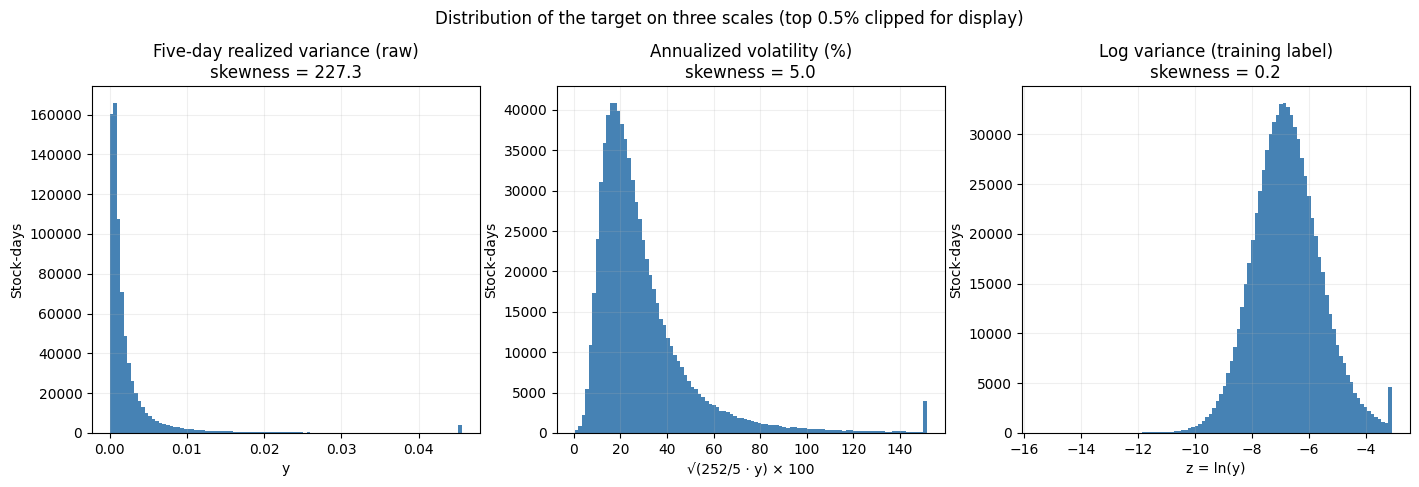

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
panels = [(eda["y_var"], "Five-day realized variance (raw)", "y"),
          (eda["rv_ann"], "Annualized volatility (%)", "√(252/5 · y) × 100"),
          (eda["z"], "Log variance (training label)", "z = ln(y)")]
for a, (s, title, xl) in zip(ax, panels):
    a.hist(s.clip(upper=s.quantile(0.995)), bins=100, color="steelblue")
    a.set(title=f"{title}\nskewness = {skew(s):.1f}", xlabel=xl, ylabel="Stock-days")
    a.grid(alpha=0.2)
fig.suptitle("Distribution of the target on three scales (top 0.5% clipped for display)", y=1.05)
save(fig, "01_target_distribution")

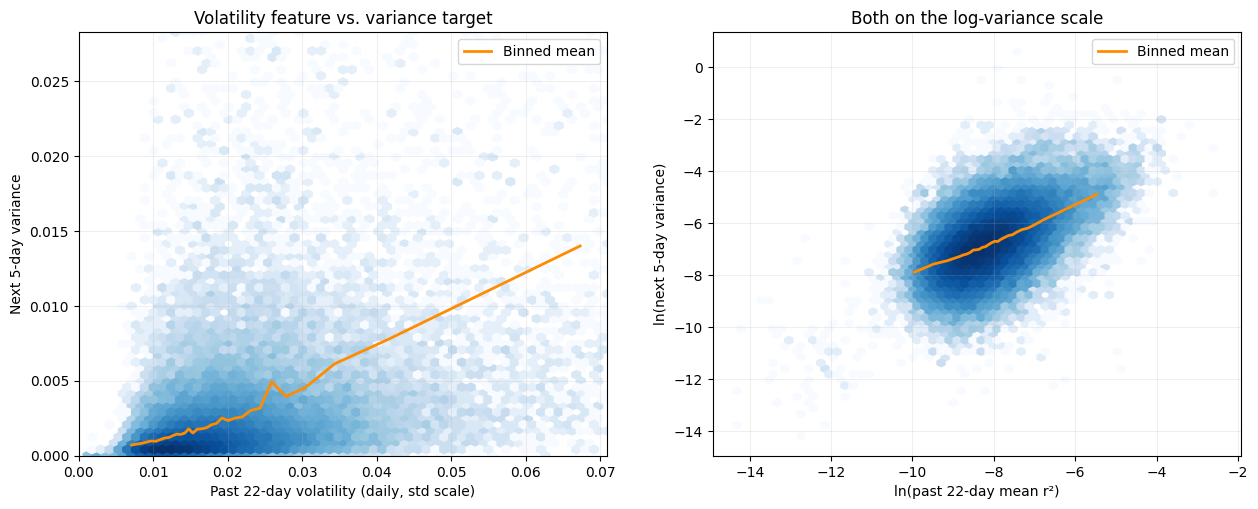

In [10]:
smp = eda.sample(60000, random_state=RS)

def binned(x, y, n=30):
    b = pd.qcut(x, n, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(b, observed=True).mean()
    return g["x"], g["y"]

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))

x0, y0 = np.sqrt(smp["rv_m"]), smp["y_var"]          # volatility-scale feature vs variance target
xmax, ymax = x0.quantile(0.99), y0.quantile(0.99)
ax[0].hexbin(x0, y0, gridsize=60, bins="log", cmap="Blues", mincnt=1, extent=(0, xmax, 0, ymax))
bx, by = binned(x0, y0); ax[0].plot(bx, by, color="darkorange", lw=2, label="Binned mean")
ax[0].set(xlim=(0, xmax), ylim=(0, ymax), xlabel="Past 22-day volatility (daily, std scale)",
          ylabel="Next 5-day variance", title="Volatility feature vs. variance target")

x1, y1 = smp["l_rv_m"], smp["z"]                      # both on log-variance scale
ax[1].hexbin(x1, y1, gridsize=60, bins="log", cmap="Blues", mincnt=1)
bx, by = binned(x1, y1); ax[1].plot(bx, by, color="darkorange", lw=2, label="Binned mean")
ax[1].set(xlabel="ln(past 22-day mean r²)", ylabel="ln(next 5-day variance)",
          title="Both on the log-variance scale")
for a in ax: a.legend(); a.grid(alpha=0.2)
save(fig, "03_feature_target_scale")

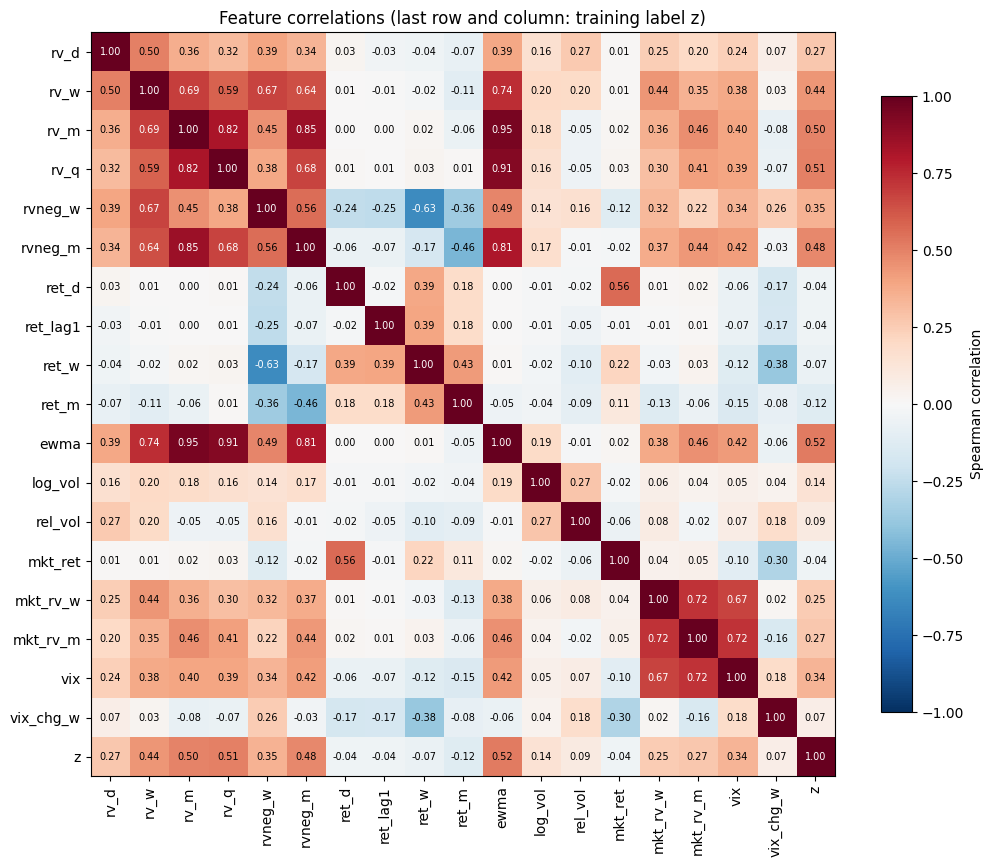

In [11]:
cols = FEATS + ["z"]
X = e.sample(100000, random_state=RS)[[("l_" + c if c in LOGF else c) for c in FEATS] + ["z"]]
X.columns = cols
corr = X.corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), cols, rotation=90)
ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation")
ax.set_title("Feature correlations (last row and column: training label z)")
save(fig, "05_feature_correlation")

## 4. Metrics and calibration

* **MAE / RMSE:** annualized volatility, percentage points.
* **QLIKE:** y/h − log(y/h) − 1 on 5-day variance (0 = perfect).
* **Bias:** mean(forecast − realized) in annualized vol pp; **Under %:** share of forecasts below realized.

Models are trained on log variance. Back-transforming exp(prediction) estimates a median, not a mean, so it is biased low. Two smearing factors are estimated on the **2024 validation predictions** (out of sample) and reused unchanged on 2025:
* c_var = mean(y / e^ẑ) for the variance forecast (QLIKE, which is minimized by the conditional mean of variance);
* c_vol = mean(√y / e^{ẑ/2}) for the volatility forecast (MAE/RMSE, position sizing).

In [12]:
EPS = 1e-10
def metrics(y, h, v=None):
    y = np.asarray(y, float); h = np.maximum(np.asarray(h, float), EPS)
    v = np.sqrt(h) if v is None else np.asarray(v, float)
    av, ah = np.sqrt(ANN * y) * 100, np.sqrt(ANN) * v * 100; err = ah - av
    q = y / h - np.log(np.maximum(y, EPS) / h) - 1
    return {"MAE": np.abs(err).mean(), "RMSE": np.sqrt((err**2).mean()), "QLIKE": q.mean(),
            "Bias": err.mean(), "Under %": (err < 0).mean() * 100}

def calib(y, zhat): return {"c_var": np.mean(y / np.exp(zhat)), "c_vol": np.mean(np.sqrt(y) / np.exp(zhat / 2))}
def back(zhat, c): return np.exp(zhat) * c["c_var"], np.exp(zhat / 2) * c["c_vol"]

def baseline(df, name):
    h = 5 * df[{"Naive_5D": "rv_w", "Hist_22D": "rv_m", "EWMA": "ewma"}[name]].to_numpy()
    return h, np.sqrt(h)
BASELINES = ["Naive_5D", "Hist_22D", "EWMA"]

## 5. Stage 1 — fit on 2020–2023, tune on 2024

* **HAR:** pooled OLS of log y on log rv_d, rv_w, rv_m (Corsi 2009).
* **Ridge:** all features, α from 1e-2 to 1e6.
* **XGBoost:** depth 4/6/8, learning rate 0.05, early stopping on 2024.
* **Random Forest:** depth 10/14, 100 trees, 20% bootstrap samples (for runtime).
* Two diagnostics: XGBoost **without market features**, and XGBoost trained on **raw variance with MSE** (the setup of the group notebook).

Hyperparameters are chosen by validation log-MSE; the model is then selected by validation QLIKE.

In [13]:
tr, va = e[e["tr"]], e[e["va"]]
Xtr, Xva, ztr, zva = Xm(tr), Xm(va), tr["z"].values, va["z"].values
STK = [c for c in FEATS if c not in MKT]
XGB_BASE = dict(learning_rate=0.05, min_child_weight=50, subsample=0.8, colsample_bytree=0.8,
                tree_method="hist", n_jobs=1, random_state=RS)
val_pred, params, tune_log = {}, {}, []
lmse = lambda zh: float(np.mean((zh - zva)**2))
t0 = time.time()

val_pred["HAR"] = LinearRegression().fit(Xm(tr, HARF), ztr).predict(Xm(va, HARF))

for a in [1e-2, 1, 1e2, 1e4, 1e5, 1e6]:
    zh = make_pipeline(StandardScaler(), Ridge(alpha=a)).fit(Xtr, ztr).predict(Xva)
    tune_log.append(("Ridge", f"alpha={a:g}", lmse(zh)))
    if "Ridge" not in params or lmse(zh) < params["Ridge"][1]: params["Ridge"] = ({"alpha": a}, lmse(zh)); val_pred["Ridge"] = zh

for d in [4, 6, 8]:
    m = xgb.XGBRegressor(n_estimators=3000, max_depth=d, early_stopping_rounds=100, eval_metric="rmse", **XGB_BASE)
    m.fit(Xtr, ztr, eval_set=[(Xva, zva)], verbose=False); zh = m.predict(Xva)
    tune_log.append(("XGBoost", f"depth={d}, trees={m.best_iteration + 1}", lmse(zh)))
    if "XGBoost" not in params or lmse(zh) < params["XGBoost"][1]:
        params["XGBoost"] = ({"max_depth": d, "n_estimators": m.best_iteration + 1}, lmse(zh)); val_pred["XGBoost"] = zh
xp = params["XGBoost"][0]

val_pred["XGBoost_no_market"] = xgb.XGBRegressor(**xp, **XGB_BASE).fit(Xm(tr, STK), ztr).predict(Xm(va, STK))
raw_var_val = xgb.XGBRegressor(**xp, **XGB_BASE).fit(Xtr, tr["y_var"].values * 1e4).predict(Xva) / 1e4

for d in [10, 14]:
    m = RandomForestRegressor(n_estimators=100, max_depth=d, min_samples_leaf=100, max_features=0.5,
                              max_samples=0.2, n_jobs=1, random_state=RS).fit(Xtr, ztr)
    zh = m.predict(Xva); tune_log.append(("RandomForest", f"depth={d}", lmse(zh)))
    if "RandomForest" not in params or lmse(zh) < params["RandomForest"][1]:
        params["RandomForest"] = ({"max_depth": d}, lmse(zh)); val_pred["RandomForest"] = zh

display(pd.DataFrame(tune_log, columns=["Model", "Setting", "Validation log-MSE"]).round(5))
print(f"Stage 1 time: {time.time() - t0:.0f}s")

,Model,Setting,Validation log-MSE
0,Ridge,alpha=0.01,1.01128
1,Ridge,alpha=1,1.01128
2,Ridge,alpha=100,1.01141
3,Ridge,alpha=10000,1.01877
4,Ridge,alpha=100000,1.03341
5,Ridge,alpha=1e+06,1.07158
6,XGBoost,"depth=4, trees=91",1.03699
7,XGBoost,"depth=6, trees=73",1.01261
8,XGBoost,"depth=8, trees=78",1.00222
9,RandomForest,depth=10,1.00242


Stage 1 time: 439s


In [14]:
y_va = va["y_var"].values
CAL, rows = {}, []
for n in BASELINES: rows.append({"Model": n, **metrics(y_va, *baseline(va, n))})
for n, zh in val_pred.items():
    CAL[n] = calib(y_va, zh); rows.append({"Model": n, **metrics(y_va, *back(zh, CAL[n]))})
rows.append({"Model": "XGBoost_raw_var (diagnostic)", **metrics(y_va, np.maximum(raw_var_val, 0))})
val_table = pd.DataFrame(rows).set_index("Model").sort_values("QLIKE")
display(val_table.round(4))

SELECTED = val_table.drop(index=BASELINES + ["XGBoost_raw_var (diagnostic)", "HAR"]).index[0]
print("Selected by validation QLIKE:", SELECTED)

,MAE,RMSE,QLIKE,Bias,Under %
Model,,,,,
XGBoost_no_market,9.3705,15.5175,0.5901,0.1584,37.7827
RandomForest,9.3395,15.4906,0.5934,0.0693,37.9202
Ridge,9.5339,15.7158,0.5944,0.2447,38.2547
XGBoost,9.3737,15.5514,0.5955,0.0714,38.0325
HAR,10.0440,16.1922,0.6658,0.6607,37.2173
EWMA,10.9893,17.4001,0.7366,2.7292,33.9930
Hist_22D,11.3596,18.1734,0.8263,2.2469,37.7945
Naive_5D,12.3855,20.6228,1.6752,0.0468,49.4592
XGBoost_raw_var (diagnostic),11.7340,18.0825,12981.1707,5.1352,24.0038


Selected by validation QLIKE: XGBoost_no_market


**Reading the validation results**

* Once features and target are on a log-variance scale, every learned model (including Ridge) clearly beats the naive 5-day baseline, and HAR is the meaningful benchmark.
* The four ML models are within about 1% of each other on QLIKE. Market features (VIX etc.) do not help in 2024, a calm year.
* The raw-variance XGBoost diagnostic reproduces the group notebook's problem: forecasts biased upward (positive Bias, low Under %) and an exploding QLIKE from near-zero variance forecasts.

## 6. Stage 2 — refit on 2020–2024, evaluate once on 2025

In [15]:
fu, te = e[e["full"]], e[e["te"]]
Xfu, Xte, zfu, y_te = Xm(fu), Xm(te), fu["z"].values, te["y_var"].values
t0 = time.time(); test_pred = {}
test_pred["HAR"] = LinearRegression().fit(Xm(fu, HARF), zfu).predict(Xm(te, HARF))
test_pred["Ridge"] = make_pipeline(StandardScaler(), Ridge(**params["Ridge"][0])).fit(Xfu, zfu).predict(Xte)
xgb_full = xgb.XGBRegressor(**xp, **XGB_BASE).fit(Xfu, zfu); test_pred["XGBoost"] = xgb_full.predict(Xte)
xgb_nm = xgb.XGBRegressor(**xp, **XGB_BASE).fit(Xm(fu, STK), zfu); test_pred["XGBoost_no_market"] = xgb_nm.predict(Xm(te, STK))
raw_var_te = xgb.XGBRegressor(**xp, **XGB_BASE).fit(Xfu, fu["y_var"].values * 1e4).predict(Xte) / 1e4
rf_full = RandomForestRegressor(n_estimators=100, min_samples_leaf=100, max_features=0.5, max_samples=0.2,
                                n_jobs=1, random_state=RS, **params["RandomForest"][0]).fit(Xfu, zfu)
test_pred["RandomForest"] = rf_full.predict(Xte)
print(f"Stage 2 time: {time.time() - t0:.0f}s")

FC = {n: baseline(te, n) for n in BASELINES}
FC.update({n: back(zh, CAL[n]) for n, zh in test_pred.items()})    # 2024 calibration factors, unchanged
FC["XGBoost_raw_var (diagnostic)"] = (np.maximum(raw_var_te, 0), np.sqrt(np.maximum(raw_var_te, 0)))
test_table = pd.DataFrame([{"Model": n, **metrics(y_te, *FC[n])} for n in FC]).set_index("Model")
for k in ["RMSE", "QLIKE"]:
    test_table[f"{k} vs HAR %"] = (test_table.loc["HAR", k] - test_table[k]) / test_table.loc["HAR", k] * 100
display(test_table.sort_values("QLIKE").round(3))

Stage 2 time: 286s


,MAE,RMSE,QLIKE,Bias,Under %,RMSE vs HAR %,QLIKE vs HAR %
Model,,,,,,,
Ridge,11.275,18.605,0.635,-0.179,37.710,4.472,8.690
XGBoost,11.442,19.354,0.645,-0.313,39.806,0.622,7.314
RandomForest,11.389,19.024,0.646,-0.377,39.604,2.318,7.195
XGBoost_no_market,11.373,18.965,0.648,-0.831,40.147,2.624,6.891
HAR,11.776,19.476,0.696,-1.021,41.067,0.000,0.000
EWMA,13.745,21.245,0.771,3.476,32.779,-9.086,-10.823
Hist_22D,13.956,21.988,0.851,2.822,36.916,-12.900,-22.269
Naive_5D,14.946,24.641,1.760,0.099,49.007,-26.523,-152.865
XGBoost_raw_var (diagnostic),14.046,21.997,30285.954,5.334,26.068,-12.944,-4352358.981


In [16]:
# Diebold–Mariano: average the loss differential across stocks each day, then Newey–West (lag 5 for overlapping 5-day targets)
def losses(n):
    h, v = FC[n]; h = np.maximum(h, EPS)
    return {"QLIKE": y_te / h - np.log(np.maximum(y_te, EPS) / h) - 1,
            "Squared error": (np.sqrt(ANN) * v * 100 - np.sqrt(ANN * y_te) * 100)**2}
def dm(a, b, kind, lag=5):
    d = pd.Series(losses(a)[kind] - losses(b)[kind]).groupby(te["date"].values).mean().values
    n, dc = len(d), d - d.mean()
    gam = [np.sum(dc[k:] * dc[:n - k]) / n for k in range(lag + 1)]
    lrv = gam[0] + 2 * sum((1 - k / (lag + 1)) * gam[k] for k in range(1, lag + 1))
    t = d.mean() / np.sqrt(lrv / n); return d.mean(), t, 2 * (1 - norm.cdf(abs(t)))
pairs = [(SELECTED, "HAR"), (SELECTED, "Naive_5D"), (SELECTED, "Ridge"), ("RandomForest", "HAR"), ("XGBoost", "XGBoost_no_market")]
dm_table = pd.DataFrame([{"Model A": a, "Model B": b, "Loss": k, "Mean diff (A−B)": m, "t": t, "p-value": pv}
                         for a, b in pairs for k in ["QLIKE", "Squared error"] for m, t, pv in [dm(a, b, k)]])
display(dm_table.round(4))
print("Negative mean diff = Model A has lower loss.")

,Model A,Model B,Loss,Mean diff (A−B),t,p-value
0,XGBoost_no_market,HAR,QLIKE,-0.0480,-3.8538,0.0001
1,XGBoost_no_market,HAR,Squared error,-19.6384,-2.8306,0.0046
2,XGBoost_no_market,Naive_5D,QLIKE,-1.1112,-7.7994,0.0000
3,XGBoost_no_market,Naive_5D,Squared error,-247.4697,-6.0591,0.0000
4,XGBoost_no_market,Ridge,QLIKE,0.0125,0.6583,0.5104
5,XGBoost_no_market,Ridge,Squared error,13.4980,1.2463,0.2127
6,RandomForest,HAR,QLIKE,-0.0501,-3.6798,0.0002
7,RandomForest,HAR,Squared error,-17.3956,-1.3210,0.1865
8,XGBoost,XGBoost_no_market,QLIKE,-0.0029,-0.6007,0.5480
9,XGBoost,XGBoost_no_market,Squared error,14.9028,0.7411,0.4586


Negative mean diff = Model A has lower loss.


In [17]:
# Errors in high-volatility outcomes (threshold: 90th percentile of realized annualized vol in the TRAIN period)
thr = np.quantile(np.sqrt(ANN * e.loc[e["tr"], "y_var"]) * 100, 0.90)
hi = np.sqrt(ANN * y_te) * 100 > thr
show = ["Naive_5D", "HAR", "Ridge", "RandomForest", "XGBoost", "XGBoost_no_market"]
regime = pd.concat({g: pd.DataFrame([{"Model": n, **metrics(y_te[m], FC[n][0][m], FC[n][1][m])} for n in show]).set_index("Model")
                    for g, m in [("High realized vol", hi), ("Other", ~hi)]})
print(f"High-vol threshold: {thr:.1f}% annualized | share of 2025 test rows: {hi.mean():.1%}")
display(regime.round(3))

High-vol threshold: 55.3% annualized | share of 2025 test rows: 7.5%


MAE    RMSE   QLIKE    Bias  Under %
                  Model                                                     
High realized vol Naive_5D           46.856  59.437  11.020 -38.716   86.627
                  HAR                47.836  58.660   3.778 -47.514   98.141
                  Ridge              43.976  55.781   3.234 -43.365   96.605
                  RandomForest       45.076  56.371   3.454 -41.499   91.795
                  XGBoost            47.649  58.304   3.506 -38.066   89.643
                  XGBoost_no_market  45.815  56.867   3.452 -45.040   96.746
Other             Naive_5D           12.352  19.220   1.007   3.254   45.950
                  HAR                 8.845  11.422   0.445   2.757   36.429
                  Ridge               8.617  11.017   0.424   3.331   32.924
                  RandomForest        8.652  11.535   0.418   2.966   35.362
                  XGBoost             8.500  11.347   0.412   2.755   35.756
                  XGBoost_no_market   8.574  11.227   0.420   2.763   35.546

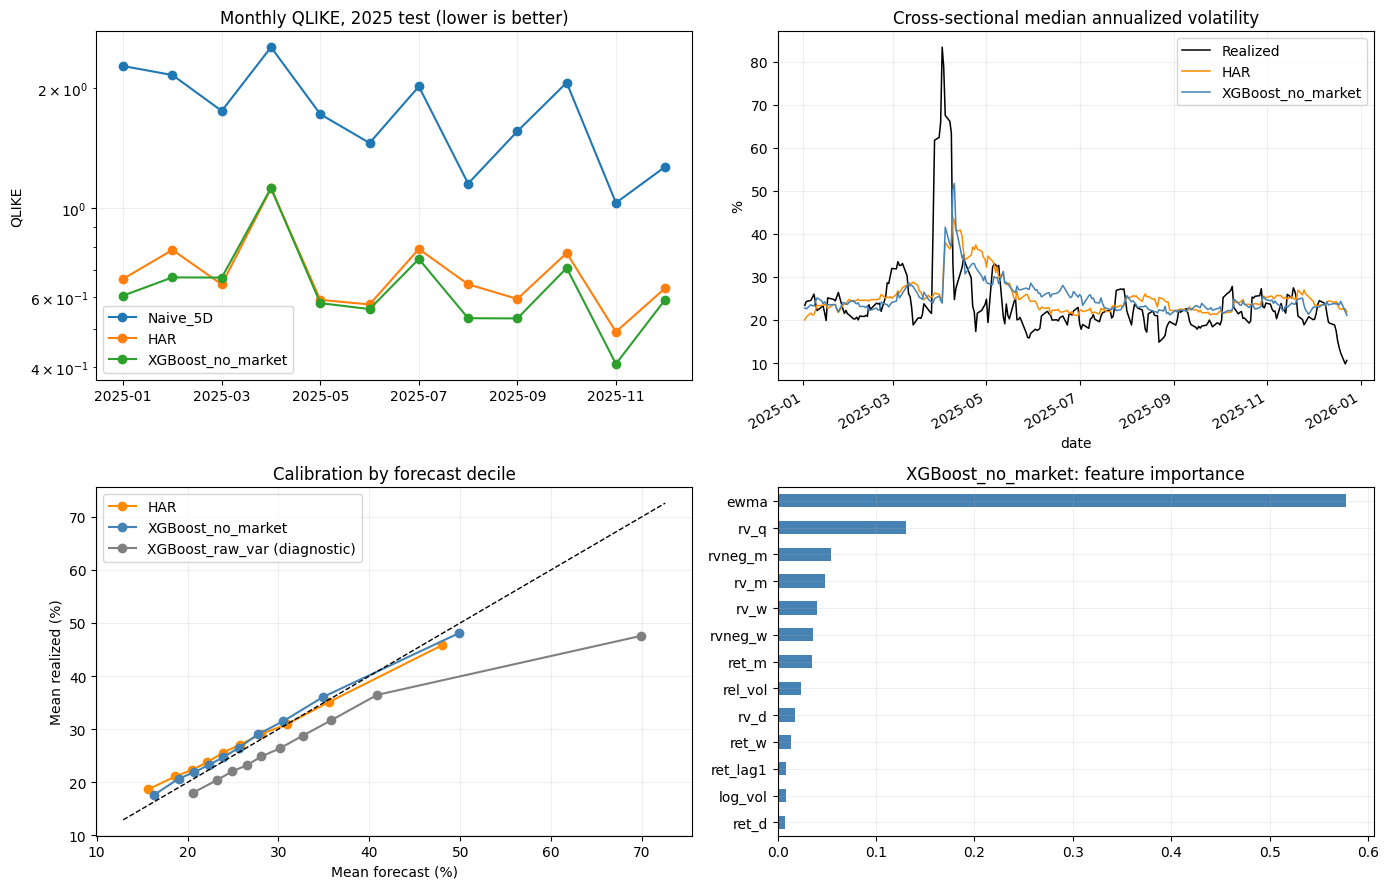

In [18]:
fig, ax = plt.subplots(2, 2, figsize=(14, 9))
month = te["date"].dt.to_period("M").values
mq = pd.DataFrame({n: pd.Series(losses(n)["QLIKE"]).groupby(month).mean() for n in ["Naive_5D", "HAR", SELECTED]})
mq.index = mq.index.astype(str); mq.plot(ax=ax[0, 0], marker="o")
ax[0, 0].set(title="Monthly QLIKE, 2025 test (lower is better)", ylabel="QLIKE", yscale="log")

daily = pd.DataFrame({"Realized": np.sqrt(ANN * y_te) * 100, "HAR": np.sqrt(ANN) * FC["HAR"][1] * 100,
                      SELECTED: np.sqrt(ANN) * FC[SELECTED][1] * 100, "date": te["date"].values}).groupby("date").median()
daily.plot(ax=ax[0, 1], lw=1.1, color=["black", "darkorange", "steelblue"])
ax[0, 1].set(title="Cross-sectional median annualized volatility", ylabel="%")

for n, col in [("HAR", "darkorange"), (SELECTED, "steelblue"), ("XGBoost_raw_var (diagnostic)", "gray")]:
    f = np.sqrt(ANN) * FC[n][1] * 100; a = np.sqrt(ANN * y_te) * 100
    b = pd.qcut(f, 10, labels=False, duplicates="drop")
    c = pd.DataFrame({"f": f, "a": a, "b": b}).groupby("b").mean()
    ax[1, 0].plot(c["f"], c["a"], marker="o", label=n, color=col)
lim = ax[1, 0].get_xlim(); ax[1, 0].plot(lim, lim, "k--", lw=1)
ax[1, 0].set(title="Calibration by forecast decile", xlabel="Mean forecast (%)", ylabel="Mean realized (%)"); ax[1, 0].legend()

imp_model = xgb_nm if SELECTED == "XGBoost_no_market" else (xgb_full if SELECTED == "XGBoost" else rf_full)
imp_cols = STK if SELECTED == "XGBoost_no_market" else FEATS
pd.Series(imp_model.feature_importances_, index=imp_cols).sort_values().plot.barh(ax=ax[1, 1], color="steelblue")
ax[1, 1].set(title=f"{SELECTED}: feature importance")
for a in ax.flat: a.grid(alpha=0.2)
plt.tight_layout(); plt.show()

## 7. Risk-budget application

Single-stock volatility targeting on non-overlapping 5-day windows in 2025: exposure w = min(1, 2% / max(σ̂₅ᴰ, 0.5%)), realized risk = w·√y.

To separate forecasting skill from overall caution, each method is also run **calibrated**: its forecast is multiplied by a constant k chosen on **2024** so that mean realized risk equals the 2% budget. The 2025 comparison then holds average risk-taking roughly equal.

In [19]:
B, FLOOR = 0.02, 0.005
def nonoverlap(df): return df["date"].isin(np.sort(df["date"].unique())[::H]).values
def expo(v, k=1.0): return np.minimum(1.0, B / np.maximum(k * v, FLOOR))
def risk_summary(v, y, k=1.0):
    w = np.ones_like(y) if v is None else expo(v, k); rr = w * np.sqrt(y); q = rr / B
    return {"Avg exposure %": w.mean() * 100, "Mean realized risk %": rr.mean() * 100,
            "Budget RMSE pp": np.sqrt(((rr - B)**2).mean()) * 100, "Over budget %": (q > 1).mean() * 100,
            "Over 1.5x %": (q > 1.5).mean() * 100, "Within ±20% %": ((q >= 0.8) & (q <= 1.2)).mean() * 100}
def solve_k(v, y):
    lo, hi_ = 0.1, 10.0
    for _ in range(60):
        k = (lo + hi_) / 2; lo, hi_ = (lo, k) if (expo(v, k) * np.sqrt(y)).mean() < B else (k, hi_)
    return k

mv, mt = nonoverlap(va), nonoverlap(te)
VFC = {n: baseline(va, n) for n in BASELINES}; VFC.update({n: back(zh, CAL[n]) for n, zh in val_pred.items()})
RM = ["Naive_5D", "EWMA", "HAR", "RandomForest", SELECTED] if SELECTED != "RandomForest" else ["Naive_5D", "EWMA", "HAR", "RandomForest"]
K = {n: solve_k(VFC[n][1][mv], y_va[mv]) for n in RM}
risk_raw = pd.DataFrame({"Unscaled": risk_summary(None, y_te[mt]), **{n: risk_summary(FC[n][1][mt], y_te[mt]) for n in RM}}).T
risk_cal = pd.DataFrame({"Unscaled": risk_summary(None, y_te[mt]), **{n: risk_summary(FC[n][1][mt], y_te[mt], K[n]) for n in RM}}).T
print(f"Decisions per method: {mt.sum():,} on {len(np.unique(te['date'].values[mt]))} dates")
print("Raw forecasts:"); display(risk_raw.round(2))
print("Calibration constants k (fit on 2024):", {n: round(k, 3) for n, k in K.items()})
print("Calibrated forecasts:"); display(risk_cal.round(2))

Decisions per method: 24,610 on 49 dates
Raw forecasts:


,Avg exposure %,Mean realized risk %,Budget RMSE pp,Over budget %,Over 1.5x %,Within ±20% %
Unscaled,100.00,3.96,3.52,81.81,54.87,20.10
Naive_5D,64.09,2.30,1.80,46.52,21.04,28.13
EWMA,53.33,1.91,1.31,33.64,11.98,29.57
HAR,58.34,2.13,1.44,41.90,15.82,32.34
RandomForest,57.14,2.06,1.33,39.33,13.00,33.80
XGBoost_no_market,57.43,2.08,1.34,40.39,14.26,33.58


Calibration constants k (fit on 2024): {'Naive_5D': 1.151, 'EWMA': 0.943, 'HAR': 0.994, 'RandomForest': 0.997, 'XGBoost_no_market': 0.996}
Calibrated forecasts:


,Avg exposure %,Mean realized risk %,Budget RMSE pp,Over budget %,Over 1.5x %,Within ±20% %
Unscaled,100.00,3.96,3.52,81.81,54.87,20.10
Naive_5D,57.67,2.06,1.62,38.38,16.33,26.43
EWMA,56.41,2.02,1.39,37.98,14.04,30.70
HAR,58.65,2.14,1.45,42.36,16.04,32.45
RandomForest,57.33,2.06,1.33,39.66,13.12,33.83
XGBoost_no_market,57.63,2.09,1.34,40.71,14.37,33.64


## 8. Summary

*(Numbers refer to the outputs above.)*

1. **Baselines.** A proper HAR benchmark is far stronger than the naive 5-day baseline. Beating HAR is the relevant test.
2. **ML vs HAR on 2025.** Every ML model beats HAR on QLIKE by roughly 7%, and the Diebold–Mariano tests reject equal QLIKE. Gains on volatility RMSE are small (about 1–4%) and only partly significant.
3. **Model choice matters little.** Ridge, Random Forest, and XGBoost are statistically indistinguishable. Once features are on a log-variance scale, most of the gain comes from the features, not from model complexity.
4. **Market features did not help.** XGBoost with and without VIX/market variables performs the same.
5. **Bias fixed.** With a log target plus out-of-sample smearing, overall bias is near zero. The raw-variance diagnostic shows the upward bias of the group setup.
6. **Large shocks remain unpredictable.** In the top 10% of realized volatility outcomes, every method underestimates in roughly 90%+ of cases.
7. **Risk application.** At equal average risk-taking, ML forecasts track the 2% budget somewhat better than HAR and naive. The advantage is modest.

**Limitations.** One validation year (2024, calm) drives selection; Random Forest uses 20% bootstrap samples for runtime; no industry classification yet; close-to-close returns only (no OHLC range estimators); stocks need 66 days of history, so new index entrants are excluded for their first ~3 months; results are pooled across stocks with correlated errors (handled in DM by daily averaging).

## Appendix — fixes for the upstream notebooks

**Acquisition, cell 9 (membership dates are inclusive):**
```python
flag = flag[(flag["date"] >= flag["start"]) & (flag["date"] <= flag["ending"])]
```
**Preparation, cell 12 (set the date index before reindexing):**
```python
vix_dt = vix_dt.set_index("observation_date")["VIXCLS"]
vix_dt = vix_dt.reindex(trading_days).ffill(limit=3)
```
**Preparation, cell 7 (use complete windows only):** keep rows with `full_r2 == True` for modeling; the annualized target for partial windows uses fewer than 5 days.

**Planned but not yet added:** industry classification (`siccd` is available in `dsf_v2`).